# 06 · Improving the probe
The probe from notebook 04 (layer 16, last answer token, logistic regression) is the **baseline**. This notebook tries to beat it without changing any baseline code or files; everything new lives in `src/improve.py`.

**Protocol.** Every candidate is scored the same way: 5-fold cross-validation on train+val (425 questions), grouped by question and repeated 3 times, with C picked from `improve.C_GRID` by CV. The test set (75 questions) is used **once**, at the end, for the baseline and the chosen model only.

**Ideas tried**
1. *Layers*: use the later layers (notebook 05 showed they carry more signal), either one layer chosen by nested CV, one probe per layer averaged, or one probe on the layer-averaged hidden state.
2. *Token position*: also average the answer tokens (`answer_mean`) or use the question's last token (`question_last`), i.e. before the model has answered.
3. *Model uncertainty*: the model's own log-probabilities and entropy on its answer tokens, stacked on top of the probe.
4. *Classifier*: PCA, shrinkage LDA and a mass-mean (difference-of-means) probe instead of plain logistic regression.
5. *Label noise*: about 40% of labels are near-ties between the good and bad reference answers. Train only on clear-cut labels (`|max_sim_incorrect − max_sim_correct| ≥ margin`); scoring always uses every example.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%load_ext autoreload
%autoreload 2
from src import config

## Extra features
One more forward pass per answer saves `answer_mean` and `question_last` hidden states at every layer, plus 5 uncertainty features, to `data/features_extra/<example_id>.npz` (~150 MB, gitignored). Existing files are reused, so the model is only loaded the first time.

In [2]:
from src.io_utils import read_jsonl
from src import improve
from src.improve import *

records = read_jsonl(config.ALL_LAYERS_DATASET_PATH)   # from notebook 05
missing = [r for r in records if not (improve.EXTRA_FEATURES_DIR / f"{r['example_id']}.npz").exists()]
if missing:
    from src.model_utils import load_model
    model, tokenizer = load_model(config.MODEL_NAME)
    extract_all_extra_features(model, tokenizer, records)
d = load_probe_data(records)
print(f'{len(missing)} extracted; pool (train+val) = {len(d.pool)}, test = {len(d.test)}')
print('hidden states:', d.answer_last.shape, '| uncertainty:', UNCERTAINTY_NAMES)

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0 extracted; pool (train+val) = 425, test = 75
hidden states: (500, 37, 2048) | uncertainty: ['mean_logprob', 'min_logprob', 'mean_entropy', 'max_entropy', 'num_tokens']


## Ablation (cross-validation only)

In [3]:
import time, numpy as np, pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

LATE = range(18, 37)          # back half of the 36 blocks
MARGIN = 0.05                 # clear-cut label threshold, see the margin sweep below
avg = {rep: layer_average(getattr(d, rep), LATE) for rep in ('answer_last', 'answer_mean', 'question_last')}
feat = lambda X: (lambda i: X[i])

def lda(f):
    def fp(tr, te):
        m = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'))
        return m.fit(f(tr), d.y[tr]).predict_proba(f(te))[:, 1]
    return fp

def mass_mean(f):
    def fp(tr, te):
        s = StandardScaler().fit(f(tr)); X = s.transform(f(tr)); y = d.y[tr]
        return s.transform(f(te)) @ (X[y == 1].mean(0) - X[y == 0].mean(0))
    return fp

L16 = feat(d.answer_last[:, 16])
candidates = [
    ('baseline', 'Baseline: layer 16, last token', lambda C: linear_probe(d, L16, C), C_GRID),
    ('labels', 'Baseline + clear-cut labels only', lambda C: linear_probe(d, L16, C, min_margin=MARGIN), C_GRID),
    ('layers', 'Best single layer (nested CV)', lambda C: auto_layer(d, 'answer_last', C), [1e-3]),
    ('layers', 'One probe per layer 18-36, averaged', lambda C: layer_ensemble(d, 'answer_last', LATE, C), [1e-3]),
    ('layers', 'Layer-averaged state 18-36', lambda C: linear_probe(d, feat(avg['answer_last']), C), C_GRID),
    ('position', 'Answer mean, layer-averaged 18-36', lambda C: linear_probe(d, feat(avg['answer_mean']), C), C_GRID),
    ('position', 'Question last token, layer-averaged 18-36', lambda C: linear_probe(d, feat(avg['question_last']), C), C_GRID),
    ('position', 'Last + mean + question, averaged', lambda C: average(*[linear_probe(d, feat(avg[r]), C) for r in avg]), C_GRID),
    ('uncertainty', 'Uncertainty features alone', lambda C: linear_probe(d, feat(d.uncertainty), C), [0.01, 0.1, 1.0]),
    ('uncertainty', 'Layer-averaged + uncertainty (stacked)', lambda C: stacked_with_uncertainty(d, linear_probe(d, feat(avg['answer_last']), C)), [1e-3]),
    ('classifier', 'Layer-averaged, PCA 64 + LR', lambda C: linear_probe(d, feat(avg['answer_last']), C, pca=64), [1e-3, 1e-2, 1e-1]),
    ('classifier', 'Layer-averaged, shrinkage LDA', lambda C: lda(feat(avg['answer_last'])), [None]),
    ('classifier', 'Layer-averaged, mass-mean probe', lambda C: mass_mean(feat(avg['answer_last'])), [None]),
    ('final', 'Layer-averaged 18-36 + clear-cut labels', lambda C: linear_probe(d, feat(avg['answer_last']), C, min_margin=MARGIN), C_GRID),
]
rows = []
for group, name, make, Cs in candidates:
    t = time.time()
    r = best_over_C(d, make, Cs)
    rows.append({'group': group, 'candidate': name, **r, 'seconds': round(time.time() - t, 1)})
ablation = pd.DataFrame(rows)
base_cv = ablation.loc[0, 'cv_auroc']
ablation['vs_baseline'] = ablation['cv_auroc'] - base_cv
ablation.round(3)

,group,candidate,C,cv_auroc,cv_std,seconds,vs_baseline
0,baseline,"Baseline: layer 16, last token",0.001,0.647,0.008,0.8,0.000
1,labels,Baseline + clear-cut labels only,0.001,0.655,0.003,0.7,0.008
2,layers,Best single layer (nested CV),0.001,0.678,0.021,25.0,0.031
3,layers,"One probe per layer 18-36, averaged",0.001,0.691,0.009,2.9,0.044
4,layers,Layer-averaged state 18-36,0.001,0.691,0.008,0.8,0.044
5,position,"Answer mean, layer-averaged 18-36",0.000,0.644,0.006,0.7,-0.003
6,position,"Question last token, layer-averaged 18-36",0.000,0.610,0.011,0.8,-0.037
7,position,"Last + mean + question, averaged",0.001,0.664,0.010,1.6,0.017
8,uncertainty,Uncertainty features alone,1.000,0.538,0.007,0.4,-0.109
9,uncertainty,Layer-averaged + uncertainty (stacked),0.001,0.678,0.004,1.4,0.031


### How strict should the label filter be?
Training on fewer but cleaner labels helps up to a margin of about 0.05, then levels off while the training set keeps shrinking. 0.05 is used above: the smallest margin on the plateau.

In [4]:
margins = []
for m in (0.0, 0.01, 0.02, 0.05, 0.08, 0.1, 0.15):
    r = best_over_C(d, lambda C: linear_probe(d, feat(avg['answer_last']), C, min_margin=m))
    margins.append({'min_margin': m, 'train_examples_kept': int((d.label_margin[d.pool] >= m).sum()), **r})
margin_sweep = pd.DataFrame(margins)
margin_sweep.round(3)

,min_margin,train_examples_kept,C,cv_auroc,cv_std
0,0.00,425,0.001,0.691,0.008
1,0.01,381,0.001,0.689,0.006
2,0.02,334,0.010,0.696,0.012
3,0.05,247,0.010,0.709,0.008
4,0.08,192,0.001,0.704,0.004
5,0.10,162,0.001,0.703,0.005
6,0.15,113,0.010,0.706,0.008


## Final test (used once)
Both models are fit on all of train+val with their CV-chosen C and scored on the 75 test questions. The baseline as shipped (`models/probe_*_L16_*.joblib`, trained on train only) is scored too. The paired bootstrap resamples test questions and compares both models on the same resample.

In [5]:
import joblib
from sklearn.metrics import roc_auc_score

base_C = ablation.loc[0, 'C']
final_C = ablation.loc[ablation['group'] == 'final', 'C'].item()
baseline_model = linear_probe(d, L16, base_C)
final_model = linear_probe(d, feat(avg['answer_last']), final_C, min_margin=MARGIN)

y_test = d.y[d.test]
shipped = joblib.load(config.MODELS_DIR / f"probe_{config.MODEL_NAME.split('/')[-1]}_L{config.LAYER_INDEX}_{config.TOKEN_POSITION_METHOD}.joblib")
p_shipped = shipped.predict_proba(d.answer_last[d.test, config.LAYER_INDEX])[:, 1]
t_base, t_final = test_auroc(d, baseline_model), test_auroc(d, final_model)

test = pd.DataFrame([
    {'model': 'Baseline as shipped (notebook 04)', 'test_auroc': roc_auc_score(y_test, p_shipped)},
    {'model': 'Baseline, same protocol', 'test_auroc': t_base['test_auroc'], 'ci95': np.round(t_base['ci95'], 3)},
    {'model': 'Improved', 'test_auroc': t_final['test_auroc'], 'ci95': np.round(t_final['ci95'], 3)},
])
vs_shipped = paired_bootstrap(y_test, p_shipped, t_final['probs'])
vs_base = paired_bootstrap(y_test, t_base['probs'], t_final['probs'])
print(f"Improved - shipped baseline: {vs_shipped['diff']:+.3f}  95% CI {np.round(vs_shipped['ci95'], 3)}  P(improved better) = {vs_shipped['p_b_better']:.2f}")
print(f"Improved - same-protocol baseline: {vs_base['diff']:+.3f}  95% CI {np.round(vs_base['ci95'], 3)}  P(improved better) = {vs_base['p_b_better']:.2f}")
test.round(3)

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site

Improved - shipped baseline: +0.064  95% CI [-0.059  0.188]  P(improved better) = 0.84
Improved - same-protocol baseline: +0.092  95% CI [-0.034  0.222]  P(improved better) = 0.91


,model,test_auroc,ci95
0,Baseline as shipped (notebook 04),0.653,NaN
1,"Baseline, same protocol",0.626,"[0.494, 0.755]"
2,Improved,0.717,"[0.588, 0.833]"


## Save
The improved probe is a single scikit-learn pipeline. Its input is the last-answer-token hidden state **averaged over layers 18–36**, i.e. `layer_average(all_layers, range(18, 37))` on a `data/hidden_states_all_layers/*.npy` array. It is refit on train+val (clear-cut labels only).

In [6]:
import json
tag = f"{config.MODEL_NAME.split('/')[-1]}_answer_last_token_L18-36avg"
tr = d.pool[d.label_margin[d.pool] >= MARGIN]
improved = improve._lr(final_C).fit(avg['answer_last'][tr], d.y[tr])
joblib.dump(improved, config.MODELS_DIR / f'probe_{tag}_improved.joblib')

summary = {
    'model_name': config.MODEL_NAME,
    'protocol': f'{CV_FOLDS}-fold CV on train+val grouped by question, repeated {CV_REPEATS}x; test used once',
    'improved_probe': {'token_position_method': 'answer_last_token', 'layers': list(LATE), 'feature': 'mean over layers',
                       'min_label_margin': MARGIN, 'C': final_C, 'train_examples': int(len(tr))},
    'ablation': ablation.drop(columns='seconds').to_dict(orient='records'),
    'margin_sweep': margin_sweep.to_dict(orient='records'),
    'test': {'baseline_shipped': float(test.loc[0, 'test_auroc']), 'baseline_same_protocol': t_base['test_auroc'],
             'baseline_same_protocol_ci95': t_base['ci95'], 'improved': t_final['test_auroc'], 'improved_ci95': t_final['ci95'],
             'improved_minus_shipped': {k: v for k, v in vs_shipped.items()},
             'improved_minus_same_protocol': {k: v for k, v in vs_base.items()}},
}
config.RESULTS_DIR.mkdir(exist_ok=True)
(config.RESULTS_DIR / f'improvement_{tag}.json').write_text(json.dumps(summary, indent=2))
ablation.to_csv(config.RESULTS_DIR / f'improvement_ablation_{tag}.csv', index=False)

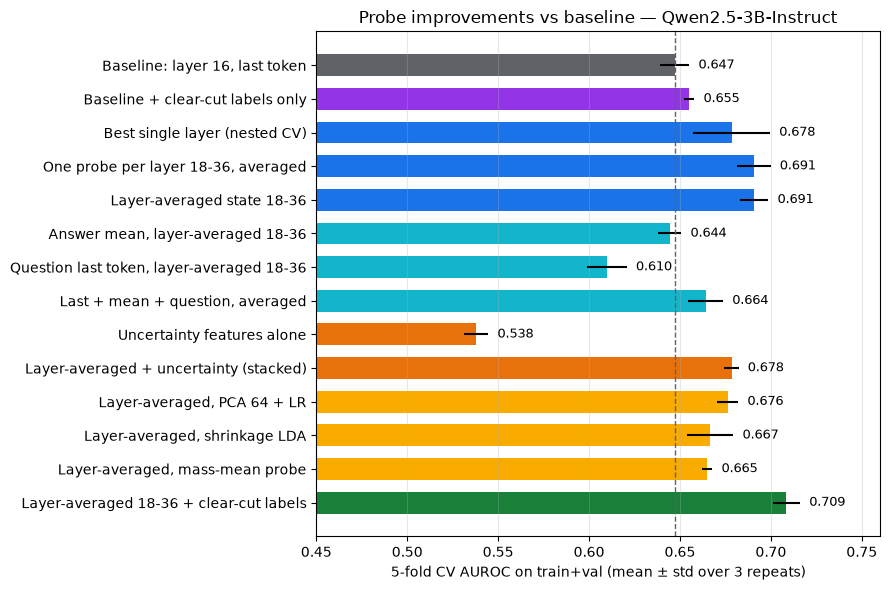

In [7]:
import matplotlib.pyplot as plt

colors = {'baseline': '#5f6368', 'labels': '#9334e6', 'layers': '#1a73e8', 'position': '#12b5cb',
          'uncertainty': '#e8710a', 'classifier': '#f9ab00', 'final': '#188038'}
a = ablation.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(a['candidate'], a['cv_auroc'], xerr=a['cv_std'], color=[colors[g] for g in a['group']], height=0.65)
ax.axvline(base_cv, color='#5f6368', ls='--', lw=1)
for y, (v, sd) in enumerate(zip(a['cv_auroc'], a['cv_std'])):
    ax.text(v + sd + 0.005, y, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(0.45, 0.76); ax.set_xlabel(f'{CV_FOLDS}-fold CV AUROC on train+val (mean ± std over {CV_REPEATS} repeats)')
ax.set_title(f"Probe improvements vs baseline — {config.MODEL_NAME.split('/')[-1]}")
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / f'improvement_ablation_{tag}.png', dpi=150)
plt.show()

## Reading the results
- **What helped:** the later layers (+0.04 CV AUROC), and training only on clear-cut labels (+0.01 to +0.02 on top). The two add up.
- **What did not:** other token positions, the model's own uncertainty, PCA, LDA and the mass-mean probe all matched or trailed plain logistic regression on the layer-averaged state.
- **Caveats:** about 25 configurations were compared on the same CV folds, so the winner's CV score is a little optimistic; the single test run is the unbiased check, but with 75 questions its interval is wide. Labels are still the main ceiling: the score is computed against noisy labels, so a better grader (e.g. an LLM judge) is the most promising next step.